In [171]:
import pandas as pd
import seaborn as sns
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error
import xgboost as xgb

In [159]:
train_df = pd.read_csv('train.csv')

<Axes: >

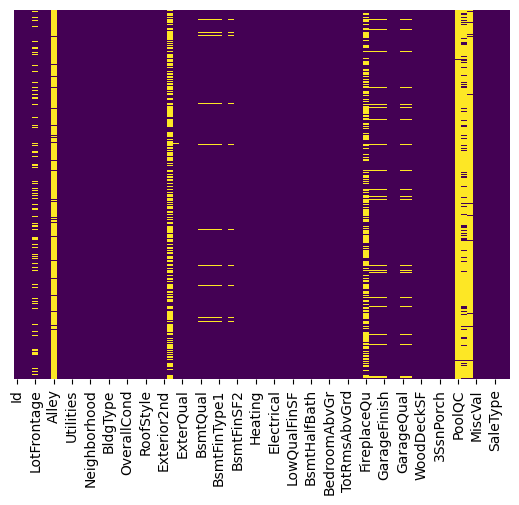

In [160]:
sns.heatmap(train_df.isnull(),yticklabels=False,cbar=False,cmap='viridis')

In [161]:
train_df.drop(['Alley','Fence','MiscFeature','Utilities','Street','MasVnrType'], axis = 1, inplace = True)

categorical_cols_with_nan = ['PoolQC', 'GarageType', 'BsmtQual', 'FireplaceQu']
for col in categorical_cols_with_nan:
    train_df[col] = train_df[col].fillna('NA')

bsmt_cols = ['BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2']
for col in bsmt_cols:
    train_df[col] = train_df[col].fillna('NA')

train_df['GarageYrBlt'] = train_df['GarageYrBlt'].fillna(-1)
train_df['GarageFinish'] = train_df['GarageFinish'].fillna('NA')
train_df['GarageQual'] = train_df['GarageQual'].fillna('NA')
train_df['GarageCond'] = train_df['GarageCond'].fillna('NA')

train_df['MasVnrArea'] = train_df['MasVnrArea'].fillna(0)

train_df['TotalSF'] = train_df['TotalBsmtSF'] + train_df['1stFlrSF'] + train_df['2ndFlrSF']
train_df['TotalBath'] = train_df['FullBath'] + (0.5*train_df['HalfBath']) + train_df['BsmtFullBath'] + (0.5*train_df['BsmtHalfBath'])
train_df['HouseAge'] = train_df['YrSold'] - train_df['YearBuilt']
train_df['TotalQual'] = train_df['OverallQual'] * train_df['OverallCond']

In [162]:
LotShapeDict = {'Reg':4,'IR1':3,'IR2':2,'IR3':1}
LandContourDict = {'Lvl':4,'Bnk':3,'HLS':2,'Low':1}
LandSlopeDict = {'Gtl':3,'Mod':2,'Sev':1}
Dict_1 = {'Ex':5,'Gd':4,'TA':3,'Fa':2,'Po':1,'NA':0}
BsmtExposureDict = {'Gd':4,'Av':3,'Mn':2,'No':1,'NA':0}
BsmtFinTypeDict = {'GLQ':6,'ALQ':5,'BLQ':4,'Rec':3,'LwQ':2,'Unf':1,'NA':0}
Dict_2 = {'Ex':5,'Gd':4,'TA':3,'Fa':2,'Po':1}
CADict = {'Y':1,'N':0}
FunctionalDict = {'Typ':8,'Min1':7,'Min2':6,'Mod':5,'Maj1':4,'Maj2':3,'Sev':2,'Sal':1}
GarageFinishDict = {'Fin':3,'RFn':2,'Unf':1,'NA':0}
PavedDriveDict = {'Y':3,'P':2,'N':1}

train_df['Ord_LotShape'] = train_df.LotShape.map(LotShapeDict)
train_df['Ord_LandContour'] = train_df.LandContour.map(LandContourDict)
train_df['Ord_LandSlope'] = train_df.LandSlope.map(LandSlopeDict)
train_df['Ord_ExterQual'] = train_df.ExterQual.map(Dict_1)
train_df['Ord_ExterCond'] = train_df.ExterCond.map(Dict_1)
train_df['Ord_BsmtQual'] = train_df.BsmtQual.map(Dict_1)
train_df['Ord_BsmtCond'] = train_df.BsmtCond.map(Dict_1)
train_df['Ord_BsmtExposure'] = train_df.BsmtExposure.map(BsmtExposureDict)
train_df['Ord_BsmtFinType1'] = train_df.BsmtFinType1.map(BsmtFinTypeDict)
train_df['Ord_BsmtFinType2'] = train_df.BsmtFinType2.map(BsmtFinTypeDict)
train_df['Ord_HeatingQC'] = train_df.HeatingQC.map(Dict_2)
train_df['Ord_CentralAir'] = train_df.CentralAir.map(CADict)
train_df['Ord_KitchenQual'] = train_df.KitchenQual.map(Dict_2)
train_df['Ord_Functional'] = train_df.Functional.map(FunctionalDict)
train_df['Ord_GarageFinish'] = train_df.GarageFinish.map(GarageFinishDict)
train_df['Ord_GarageQual'] = train_df.GarageQual.map(Dict_1)
train_df['Ord_GarageCond'] = train_df.GarageCond.map(Dict_1)
train_df['Ord_PavedDrive'] = train_df.PavedDrive.map(PavedDriveDict)

train_df = train_df.drop(['LotShape','LandContour','LandSlope','ExterQual','ExterCond','BsmtQual',
                          'BsmtCond','BsmtExposure','BsmtFinType1','BsmtFinType2',
                          'HeatingQC','CentralAir','KitchenQual','Functional','GarageFinish','GarageQual',
                          'GarageCond','PavedDrive','SaleType'], axis=1)
train_df.drop(['Id'], axis=1, inplace=True) 

In [163]:
num_count = train_df.select_dtypes(include='number').shape[1]
obj_count = train_df.select_dtypes(include='object').shape[1]
cat_count = train_df.select_dtypes(include='category').shape[1]
print('Numeric columns:', num_count)
print('Object columns:', obj_count)
print('Categorical columns:', cat_count)

Numeric columns: 60
Object columns: 18
Categorical columns: 0


In [164]:
y_tr = train_df['SalePrice']
X_tr = train_df.drop(['SalePrice'], axis=1, inplace=False)
X_train, X_test, y_train, y_test = train_test_split(X_tr, y_tr, test_size=0.2, shuffle=True)

In [165]:
train_medians = X_train.groupby('Neighborhood')['LotFrontage'].median()

def fill_lot_frontage(df, medians):
    df['LotFrontage'] = df['LotFrontage'].fillna(df['Neighborhood'].map(medians))
    df['LotFrontage'] = df['LotFrontage'].fillna(medians.median())
    return df

X_train = fill_lot_frontage(X_train, train_medians)
X_test = fill_lot_frontage(X_test, train_medians)

categorical_features = X_train.select_dtypes(include='object').columns
for col in categorical_features:
    X_train[col] = X_train[col].fillna('None')
    X_train[col] = X_train[col].astype('category')
    X_test[col] = X_test[col].fillna('None')
    X_test[col] = X_test[col].astype('category')
    train_categories = set(X_train[col].unique())
    X_test[col] = X_test[col].apply(lambda x: x if x in train_categories else 'Other')
    if 'Other' not in train_categories:
        X_train[col] = X_train[col].astype('category').cat.add_categories(['Other'])
    else:
        X_train[col] = X_train[col].astype('category')
    X_test[col] = X_test[col].astype('category').cat.set_categories(X_train[col].cat.categories)

In [183]:
model = xgb.XGBRegressor(objective='reg:absoluteerror',
                         n_estimators=1000,
                         learning_rate=0.05,
                         max_depth=6,
                         enable_categorical=True,
                         early_stopping_rounds=50)
model.fit(X_train, y_train,
         eval_set=[(X_test, y_test)],
         verbose=50)

[0]	validation_0-mae:55245.36986
[50]	validation_0-mae:20709.67051
[100]	validation_0-mae:17340.26961
[150]	validation_0-mae:15838.05616
[200]	validation_0-mae:15490.14707
[250]	validation_0-mae:15406.74981
[300]	validation_0-mae:15296.71808
[350]	validation_0-mae:15219.59704
[400]	validation_0-mae:15142.52338
[433]	validation_0-mae:15156.17214


,"objective objective: typing.Union[str, xgboost.sklearn._SklObjWProto, typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]], NoneType]Specify the learning task and the corresponding learning objective or a customobjective function to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'reg:absoluteerror'
,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API `... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",50
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes f

In [184]:
pred = model.predict(X_test)

In [185]:
print(mean_absolute_error(y_test, pred))

15114.05859375


In [191]:
# Преобразуем датафрейм serving_df
serving_df = pd.read_csv('test.csv')
serving_df_id = serving_df['Id']
serving_df.drop(['Id'], axis=1, inplace=True)

In [192]:
serving_df.drop(['Alley','Fence','MiscFeature','Utilities','Street','MasVnrType'], axis = 1, inplace = True)

categorical_cols_with_nan = ['PoolQC', 'GarageType', 'BsmtQual', 'FireplaceQu']
for col in categorical_cols_with_nan:
    serving_df[col] = serving_df[col].fillna('NA')

bsmt_cols = ['BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2']
for col in bsmt_cols:
    serving_df[col] = serving_df[col].fillna('NA')

serving_df['GarageYrBlt'] = serving_df['GarageYrBlt'].fillna(-1)
serving_df['GarageFinish'] = serving_df['GarageFinish'].fillna('NA')
serving_df['GarageQual'] = serving_df['GarageQual'].fillna('NA')
serving_df['GarageCond'] = serving_df['GarageCond'].fillna('NA')

serving_df['MasVnrArea'] = serving_df['MasVnrArea'].fillna(0)

serving_df['TotalSF'] = serving_df['TotalBsmtSF'] + serving_df['1stFlrSF'] + serving_df['2ndFlrSF']
serving_df['TotalBath'] = serving_df['FullBath'] + (0.5*serving_df['HalfBath']) + serving_df['BsmtFullBath'] + (0.5*serving_df['BsmtHalfBath'])
serving_df['HouseAge'] = serving_df['YrSold'] - serving_df['YearBuilt']
serving_df['TotalQual'] = serving_df['OverallQual'] * serving_df['OverallCond']

serving_df['Ord_LotShape'] = serving_df.LotShape.map(LotShapeDict)
serving_df['Ord_LandContour'] = serving_df.LandContour.map(LandContourDict)
serving_df['Ord_LandSlope'] = serving_df.LandSlope.map(LandSlopeDict)
serving_df['Ord_ExterQual'] = serving_df.ExterQual.map(Dict_1)
serving_df['Ord_ExterCond'] = serving_df.ExterCond.map(Dict_1)
serving_df['Ord_BsmtQual'] = serving_df.BsmtQual.map(Dict_1)
serving_df['Ord_BsmtCond'] = serving_df.BsmtCond.map(Dict_1)
serving_df['Ord_BsmtExposure'] = serving_df.BsmtExposure.map(BsmtExposureDict)
serving_df['Ord_BsmtFinType1'] = serving_df.BsmtFinType1.map(BsmtFinTypeDict)
serving_df['Ord_BsmtFinType2'] = serving_df.BsmtFinType2.map(BsmtFinTypeDict)
serving_df['Ord_HeatingQC'] = serving_df.HeatingQC.map(Dict_2)
serving_df['Ord_CentralAir'] = serving_df.CentralAir.map(CADict)
serving_df['Ord_KitchenQual'] = serving_df.KitchenQual.map(Dict_2)
serving_df['Ord_Functional'] = serving_df.Functional.map(FunctionalDict)
serving_df['Ord_GarageFinish'] = serving_df.GarageFinish.map(GarageFinishDict)
serving_df['Ord_GarageQual'] = serving_df.GarageQual.map(Dict_1)
serving_df['Ord_GarageCond'] = serving_df.GarageCond.map(Dict_1)
serving_df['Ord_PavedDrive'] = serving_df.PavedDrive.map(PavedDriveDict)

serving_df = serving_df.drop(['LotShape','LandContour','LandSlope','ExterQual','ExterCond','BsmtQual',
                          'BsmtCond','BsmtExposure','BsmtFinType1','BsmtFinType2',
                          'HeatingQC','CentralAir','KitchenQual','Functional','GarageFinish','GarageQual',
                          'GarageCond','PavedDrive','SaleType'], axis=1)

In [193]:
serving_df = fill_lot_frontage(serving_df, train_medians)

for col in categorical_features:
    serving_df[col] = serving_df[col].fillna('None').astype(str)
    train_categories = set(X_train[col].unique())
    serving_df[col] = serving_df[col].apply(lambda x: x if x in train_categories else 'Other')
    serving_df[col] = serving_df[col].astype('category').cat.set_categories(X_train[col].cat.categories)

In [194]:
serv_pred = model.predict(serving_df)

In [195]:
arr_id = serving_df_id.to_numpy()
output_dict = {'Id': arr_id, 'SalePrice': serv_pred}
output_df = pd.DataFrame(output_dict)
output_df = output_df.astype(str)
output_df.to_csv('housing_results_2.csv',sep=',',index=False)